---
title: 3.4.b Amenaza — Calor extremo
short_title: b. Amenaza
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/sincelejo/blob/main/book/03_analisis/34_calor/b_amenaza.ipynb)

**Reproducible sin red en el checkout.** La fuente preservada y sus limitaciones se describen en el capítulo 2.3.


In [1]:
from pathlib import Path
import sys, subprocess, json
candidatos = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p/'src/sincelejo/analisis.py').exists()), None)
if ROOT is None:
    ROOT = Path('/content/sincelejo')
    if not ROOT.exists():
        subprocess.run(['git','clone','https://github.com/mromerot/sincelejo.git',str(ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(ROOT)+'[libro]'],check=True)
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sincelejo.analisis import cargar, indicadores, deficit_trimestral, sensibilidad_calor
clima = cargar(ROOT/'data/raw/power_1991_2025.json')
anual = indicadores(clima)
evidencia = pd.read_json(ROOT/'data/evidencia.json')
plt.rcParams.update({'figure.figsize':(9,4), 'axes.spines.top':False, 'axes.spines.right':False})


## Método

Se calculan TX35, noches TN25 y excedencias del percentil 90 mensual. La sensibilidad suma 1–3 °C a máxima y mínima históricas. No se calcula UTCI/WBGT con medias diarias incompletas, ni se combina máxima diaria con humedad media para aparentar un máximo de índice de calor.

,tmedia,tx35,noches25,tx90_mes
anio,,,,
1991,27.77,70,159,22
1992,27.92,85,165,31
1993,27.71,52,156,11
1994,27.52,55,136,11
1995,27.62,58,144,16
1996,27.62,57,126,15
1997,28.55,127,213,95
1998,28.31,103,241,62
1999,27.11,31,93,6


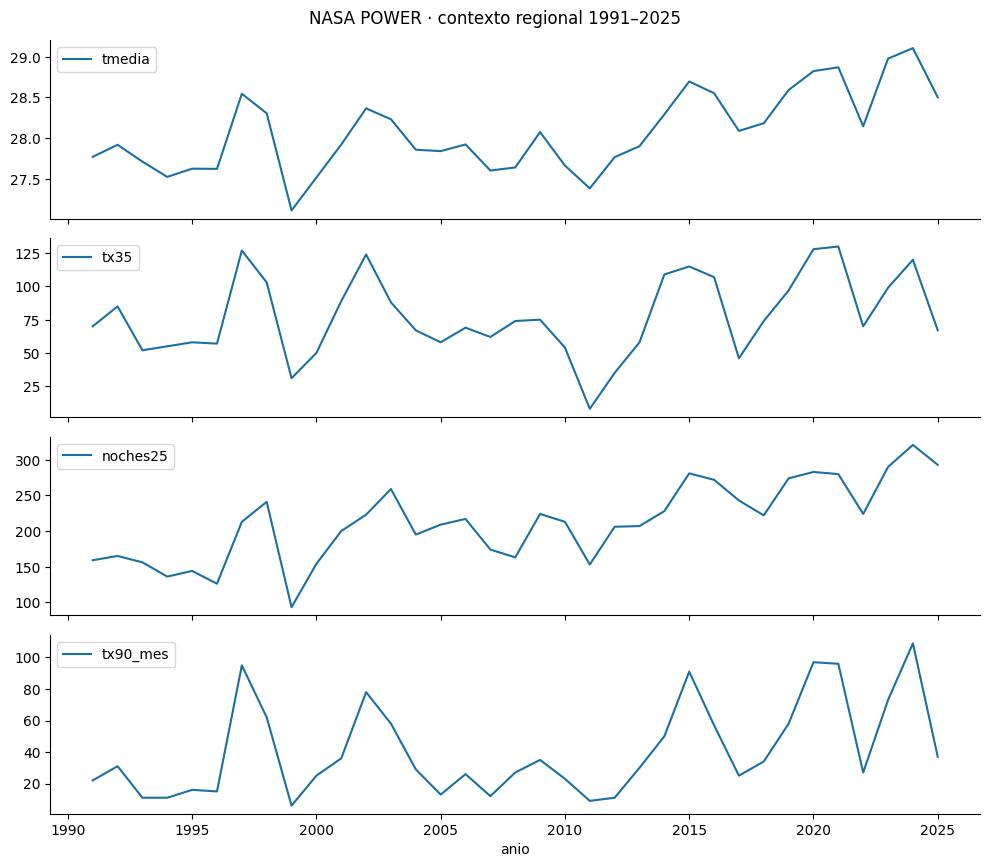

In [2]:
columnas = ['tmedia', 'tx35', 'noches25', 'tx90_mes']
display(anual[columnas].round(2))
anual[columnas].plot(subplots=True,figsize=(10,8.8),color='#1a6fa3',legend=True)
plt.suptitle('NASA POWER · contexto regional 1991–2025'); plt.tight_layout(); plt.show()

## Interpretación

Se cuantifican días y noches calurosos del entorno regional. No se estiman muertes, consultas o productividad perdida; los umbrales empleados no sustituyen una relación epidemiológica local.

Para el vínculo con exposición y vulnerabilidad continúe con [riesgo](c_riesgo.ipynb).